## Bimodal Switches

Like seen in [Drijfhout et al., 2015].

In [5]:
import numpy as np
import matplotlib.pyplot as plt

central_time = 50
interval_length = -13
duration = None
magnitude = -1.0

def make_shift(
        time_arr,
        time_offset= 0,
):

    if interval_length == 0:    # raise error as otherwise infinite loop occurs
        raise ValueError("Interval length cannot be zero.")

    t_shift = central_time + time_offset
    shift_effect = np.zeros_like(time_arr)
    j = 0

    if interval_length > 0:
        # Forward iteration
        while (central_time + interval_length * j) < len(time_arr):
            start = int(central_time + interval_length * j)
            end = int(central_time + interval_length * (j + 1))
            shift_effect[start:end] = magnitude
            j += 2
    else:
        # Backward iteration
        while (central_time + interval_length * j) >= 0:
            start = int(central_time + interval_length * j)
            end = int(central_time + interval_length * (j + 1))
            shift_effect[end:start] = magnitude
            j += 2

    return shift_effect, t_shift 


In [71]:
import numpy as np
import matplotlib.pyplot as plt

central_time = 35
interval_length = -3
duration = None
magnitude = 1.5

def make_shift(
        time_arr,
        time_offset= 0,
):

    if interval_length == 0:    # raise error as otherwise infinite loop occurs
        raise ValueError("Interval length cannot be zero.")

    t_shift = central_time + time_offset
    shift_effect = np.zeros_like(time_arr)

    # bootstrap loop
    start = int(central_time)
    end = int(central_time + interval_length)
    j = 0

    # Forward iteration
    while not(start > len(time_arr)) and not(start <= 0):
        #print(f"{start=}; {end=}")
        if interval_length > 0:         # Forward
            end = min(len(time_arr), end)
            shift_effect[start:end] = magnitude
        else:                           # Backward
            end = max(0, end)
            shift_effect[end:start] = magnitude

        j += 2
        start = int(central_time + interval_length * j)
        end = int(central_time + interval_length * (j + 1))

    return shift_effect, t_shift 


Shift Effect: [0.  0.  1.5 1.5 1.5 0.  0.  0.  1.5 1.5 1.5 0.  0.  0.  1.5 1.5 1.5 0.
 0.  0.  1.5 1.5 1.5 0.  0.  0.  1.5 1.5 1.5 0.  0.  0.  1.5 1.5 1.5 0.
 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
Time of Shift: 35


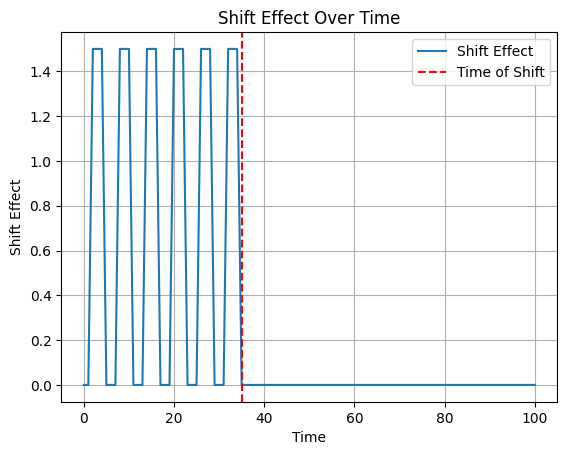

In [72]:
time_arr = np.linspace(0, 100, 101)

shift_effect, t_shift = make_shift(time_arr, time_offset=0)

print("Shift Effect:", shift_effect)
print("Time of Shift:", t_shift)

plt.plot(time_arr, shift_effect, label='Shift Effect')
plt.axvline(x=t_shift, color='r', linestyle='--', label='Time of Shift')
plt.title("Shift Effect Over Time")
plt.xlabel("Time")
plt.ylabel("Shift Effect")
plt.legend()
plt.grid()
plt.show()
